In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import(
    accuracy_score,
    confusion_matrix,
    classification_report
)

In [6]:
df = pd.read_csv("student-mat-clean (1).csv")
print("Dataset shape:", df.shape)
df.head()
print(df.columns.tolist())

Dataset shape: (395, 33)
['school', 'gender', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'FinalGrade']


In [7]:
df["Pass"] = (df["FinalGrade"] >= 10).astype(int)
df[["FinalGrade", "Pass"]].head(15)

print("0 = Fail")
print("1 = Pass")
print("\nNumber of students:")
print(df["Pass"].value_counts())
print("\nPercentage:")
print(df["Pass"].value_counts(normalize=True) * 100)

0 = Fail
1 = Pass

Number of students:
Pass
1    265
0    130
Name: count, dtype: int64

Percentage:
Pass
1    67.088608
0    32.911392
Name: proportion, dtype: float64


In [8]:
features = [
    "age", "Medu", "Fedu", "studytime",
    "failures", "famrel", "freetime", "goout",
    "Dalc", "Walc", "health", "absences"
]

X = df[features]
y = df["Pass"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (395, 12)
y shape: (395,)


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 316
Testing samples: 79


# **PART 2 BASELINE LOGISTICE REGRESSION**

### 4.1 Train and predict

In [11]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print(y_pred[:20])

[0 0 1 1 1 1 1 0 1 1 1 1 1 1 0 1 0 1 1 1]


### 4.2 Accuracy

In [12]:
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)
print("Accuracy: {:.2f}%".format(accuracy * 100))

Accuracy: 0.6582278481012658
Accuracy: 65.82%


### 4.3 Confusion matrix

[[ 7 19]
 [ 8 45]]


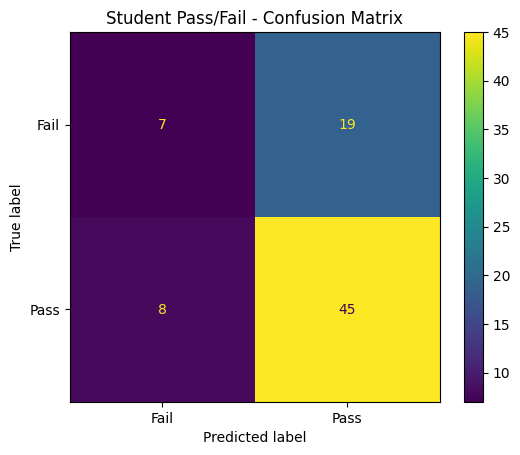

In [13]:
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Fail", "Pass"]
)
disp.plot()
plt.title("Student Pass/Fail - Confusion Matrix")
plt.show()

### 4.4 Classification report

In [14]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Fail", "Pass"]
    )
)

              precision    recall  f1-score   support

        Fail       0.47      0.27      0.34        26
        Pass       0.70      0.85      0.77        53

    accuracy                           0.66        79
   macro avg       0.58      0.56      0.56        79
weighted avg       0.63      0.66      0.63        79



### 5.1 Create five folds

In [15]:
from sklearn.model_selection import StratifiedKFold

k = 5
skf = StratifiedKFold(
    n_splits=k,
    shuffle=True,
    random_state=42
)

### 5.2 Inspect fold sizes

In [16]:
fold = 1
for train_index, val_index in skf.split(X_train, y_train):
    print(f"Fold {fold}")
    print("Training samples:", len(train_index))
    print("Validation samples:", len(val_index))
    print("-------------------------")
    fold += 1

Fold 1
Training samples: 252
Validation samples: 64
-------------------------
Fold 2
Training samples: 253
Validation samples: 63
-------------------------
Fold 3
Training samples: 253
Validation samples: 63
-------------------------
Fold 4
Training samples: 253
Validation samples: 63
-------------------------
Fold 5
Training samples: 253
Validation samples: 63
-------------------------


### 5.3 Train and validate each fold

In [17]:
fold_scores = []
fold = 1

for train_index, val_index in skf.split(X_train, y_train):

    X_fold_train = X_train.iloc[train_index]
    y_fold_train = y_train.iloc[train_index]

    X_fold_val = X_train.iloc[val_index]
    y_fold_val = y_train.iloc[val_index]

    model = LogisticRegression(max_iter=1000)
    model.fit(X_fold_train, y_fold_train)

    y_fold_pred = model.predict(X_fold_val)
    score = accuracy_score(y_fold_val, y_fold_pred)

    fold_scores.append(score)
    print(f"Fold {fold} Validation_Accuracy: {score:.3f}")
    fold += 1

Fold 1 Validation_Accuracy: 0.672
Fold 2 Validation_Accuracy: 0.683
Fold 3 Validation_Accuracy: 0.683
Fold 4 Validation_Accuracy: 0.714
Fold 5 Validation_Accuracy: 0.794


In [18]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

baseline_model = LogisticRegression(max_iter=1000)
baseline_model.fit(X_train, y_train)
baseline_pred = baseline_model.predict(X_test)

baseline_accuracy = accuracy_score(y_test, baseline_pred)

print("Baseline Test Accuracy:", round(baseline_accuracy, 3))
print("Baseline Test Accuracy: {:.2f}%".format(baseline_accuracy * 100))

Baseline Test Accuracy: 0.658
Baseline Test Accuracy: 65.82%


In [19]:
from sklearn.model_selection import StratifiedKFold
import numpy as np

k = 5
skf = StratifiedKFold(
    n_splits=k,
    shuffle=True,
    random_state=42
)

C_values = [0.01, 0.1, 1, 10, 100]
cv_results = []

for C in C_values:

    fold_scores = []

    for train_index, val_index in skf.split(X_train, y_train):

        X_fold_train = X_train.iloc[train_index]
        X_fold_val = X_train.iloc[val_index]

        y_fold_train = y_train.iloc[train_index]
        y_fold_val = y_train.iloc[val_index]

        model = LogisticRegression(C=C, max_iter=1000)
        model.fit(X_fold_train, y_fold_train)

        y_fold_pred = model.predict(X_fold_val)
        score = accuracy_score(y_fold_val, y_fold_pred)
        fold_scores.append(score)

    mean_score = np.mean(fold_scores)
    std_score = np.std(fold_scores)

    cv_results.append({
        "C": C,
        "Mean CV Accuracy": mean_score,
        "Std": std_score
    })

    print(
        f"C = {C} | "
        f"Mean Accuracy = {mean_score:.3f} | "
        f"Std = {std_score:.3f}"
    )

C = 0.01 | Mean Accuracy = 0.693 | Std = 0.025
C = 0.1 | Mean Accuracy = 0.718 | Std = 0.046
C = 1 | Mean Accuracy = 0.709 | Std = 0.045
C = 10 | Mean Accuracy = 0.709 | Std = 0.045
C = 100 | Mean Accuracy = 0.709 | Std = 0.045


In [20]:
## Resources

### 6.4 Create the comparison table
results_df = pd.DataFrame(cv_results)

results_df["Mean CV Accuracy"] = (
    results_df["Mean CV Accuracy"] * 100
)

results_df["Std"] = (
    results_df["Std"] * 100
)

print(results_df.to_markdown(index=False))

### 6.5 Select the best C
best_index = results_df["Mean CV Accuracy"].idxmax()
best_C = results_df.loc[best_index, "C"]
print("Best C selected by 5-Fold CV:", best_C)

### 6.6 Train final model
final_model = LogisticRegression(
    C=best_C,
    max_iter=1000
)

# Train using ALL training data
final_model.fit(X_train, y_train)

# Predict on untouched test data
final_pred = final_model.predict(X_test)

# Final test accuracy
final_accuracy = accuracy_score(y_test, final_pred)

print("Final Test Accuracy:", round(final_accuracy, 3))
print("Final Test Accuracy: {:.2f}%".format(final_accuracy * 100))

### 6.7 Compare baseline and K-Fold-selected model
print("===== Accuracy Comparison =====")

print(
    "Baseline Test Accuracy: "
    "{:,.2f}%".format(baseline_accuracy * 100)
)

print(
    "K-Fold Selected Test Accuracy: "
    "{:,.2f}%".format(final_accuracy * 100)
)

print(
    "Difference: "
    "{:+.2f} percentage points".format(
        (final_accuracy - baseline_accuracy) * 100
    )
)

|      C |   Mean CV Accuracy |     Std |
|-------:|-------------------:|--------:|
|   0.01 |            69.2956 | 2.46423 |
|   0.1  |            71.8353 | 4.64137 |
|   1    |            70.8978 | 4.46593 |
|  10    |            70.8978 | 4.46593 |
| 100    |            70.8978 | 4.46593 |
Best C selected by 5-Fold CV: 0.1
Final Test Accuracy: 0.684
Final Test Accuracy: 68.35%
===== Accuracy Comparison =====
Baseline Test Accuracy: 65.82%
K-Fold Selected Test Accuracy: 68.35%
Difference: +2.53 percentage points
